<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/neural-networks/Atividade_2_Backprop_Otimizacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade Avaliativa 2 — *Backpropagation* e Otimização

**Fundamentos de Redes Neurais Artificiais** · Conteúdo dos Laboratórios 3 e 4

Você já tem todo o código das aulas: o *forward* do Lab 2, o *backward* e o *gradient check* do Lab 3, a inicialização
e a classe `MLP` do Lab 4. Ninguém vai reimplementá-los do zero. A tarefa é **usar, interpretar e estender** esse código
na base **Iris**, com **as mesmas 120 flores, o mesmo `h` e a mesma ativação da Parte B da Atividade 1**.

### Regras

- **Cada aluno tem os seus próprios dados.** Amostras, pesos, arquitetura e defeitos são sorteados a partir da
  sua matrícula, então as suas respostas são diferentes das dos colegas.
- Responda **atribuindo a resposta correta às variáveis indicadas** (`q1_delta2 = ...` etc.), calculada com os seus dados.
  Você pode digitar o resultado da sua conta ou deixar a linha calcular com código; um número qualquer vale zero.
  Não renomeie as variáveis.
- **Não altere** as células marcadas com 🔒. A correção usa a versão original delas.
- A correção é **automática**: o notebook será executado do início ao fim. Se ele parar com erro,
  as respostas das células seguintes podem ser perdidas.

### Como entregar

1. Antes de baixar, use **Ambiente de execução → Reiniciar sessão e executar tudo** e confira se não há erros.
2. Rode a célula **Verificação final** no fim do notebook.
3. **Arquivo → Fazer download → Baixar o .ipynb**, anexe esse arquivo na atividade do **Google Classroom** e clique em **Entregar**.

## Identificação

Preencha com a sua matrícula **do SIGAA**, só os dígitos, sem aspas, e o seu nome completo, entre aspas.

In [1]:
MATRICULA = 20262007206      # ex.: MATRICULA = 20261234
NOME = "Jessica Matias Lewinter"            # ex.: NOME = "Maria Aparecida da Silva"

## 🔒 O código das aulas

O mesmo código dos Labs 2, 3 e 4: as ativações com as derivadas, as perdas, `inicializa` (com `'zeros'`, `'xavier'`, `'he'`
ou um número), `forward`, `backward`, `gradient_check` e a classe `MLP`. No fim vem a `forward_geral` da Atividade 1,
já pronta, e o dicionário `PERDAS` com o par saída-perda de cada tarefa.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (5.2, 4.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
AZUL, VERMELHO, VERDE, TINTA, CINZA = "#7C90B0", "#DB1E2F", "#2E8B8B", "#231F20", "#5F5A5C"


# ---- Ativações (função, derivada) ----
def sigmoid(Z): return 1.0 / (1.0 + np.exp(-np.clip(Z, -500, 500)))
def relu(Z): return np.maximum(0, Z)

ATIVACOES = {
    "sigmoid": (sigmoid, lambda Z: sigmoid(Z) * (1 - sigmoid(Z))),
    "tanh":    (np.tanh, lambda Z: 1 - np.tanh(Z) ** 2),
    "relu":    (relu,    lambda Z: (Z > 0).astype(float)),
}

def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)


# ---- Perdas ----
def mse(Y, Y_hat):
    return np.mean((Y - Y_hat) ** 2)

def bce(Y, Y_hat, eps=1e-12):
    Y_hat = np.clip(Y_hat, eps, 1 - eps)
    return -np.mean(Y * np.log(Y_hat) + (1 - Y) * np.log(1 - Y_hat))

def cce(Y, Y_hat, eps=1e-12):                  # Y em one-hot, shape (m, k)
    Y_hat = np.clip(Y_hat, eps, 1.0)
    return -np.mean(np.sum(Y * np.log(Y_hat), axis=1))

def one_hot(y, k):
    Y = np.zeros((len(y), k))
    Y[np.arange(len(y)), y] = 1
    return Y


# ---- Inicialização (Lab 4): 'zeros', 'xavier', 'he' ou um número (o desvio padrão) ----
def inicializa(camadas, metodo="he", seed=0):
    rng = np.random.default_rng(seed)
    params = {}
    for l in range(1, len(camadas)):
        n_in, n_out = camadas[l-1], camadas[l]
        if metodo == "zeros":
            sigma = 0.0
        elif metodo == "xavier":
            sigma = np.sqrt(1 / n_in)
        elif metodo == "he":
            sigma = np.sqrt(2 / n_in)
        else:
            sigma = float(metodo)
        params[f"W{l}"] = rng.normal(0, 1, (n_in, n_out)) * sigma
        params[f"b{l}"] = np.zeros((1, n_out))
    return params


# ---- Forward (Lab 2) e backward (Lab 3) ----
def forward(X, params, ativacao="relu"):
    g, _ = ATIVACOES[ativacao]
    L = len(params) // 2
    cache = {"A0": X}
    A = X
    for l in range(1, L):
        Z = A @ params[f"W{l}"] + params[f"b{l}"]
        A = g(Z)
        cache[f"Z{l}"], cache[f"A{l}"] = Z, A
    ZL = A @ params[f"W{L}"] + params[f"b{L}"]
    AL = softmax(ZL)
    cache[f"Z{L}"], cache[f"A{L}"] = ZL, AL
    return AL, cache

def backward(Y, params, cache, ativacao="relu"):
    _, dg = ATIVACOES[ativacao]
    L = len(params) // 2
    m = Y.shape[0]
    grads = {}
    dZ = (cache[f"A{L}"] - Y) / m                              # (a)
    for l in range(L, 0, -1):
        A_prev = cache[f"A{l-1}"]
        grads[f"dW{l}"] = A_prev.T @ dZ                        # (b)
        grads[f"db{l}"] = dZ.sum(axis=0, keepdims=True)
        if l > 1:                                              # (c)
            dZ = (dZ @ params[f"W{l}"].T) * dg(cache[f"Z{l-1}"])
    return grads


# ---- Gradient checking (Lab 3) ----
def gradient_check(X, Y, params, ativacao="tanh", eps=1e-6, backward_fn=backward):
    AL, cache = forward(X, params, ativacao)
    grads = backward_fn(Y, params, cache, ativacao)
    erros = {}
    for chave, P in params.items():
        numerico = np.zeros_like(P)
        for ind in np.ndindex(P.shape):
            original = P[ind]
            P[ind] = original + eps
            J_mais = cce(Y, forward(X, params, ativacao)[0])
            P[ind] = original - eps
            J_menos = cce(Y, forward(X, params, ativacao)[0])
            P[ind] = original                          # restaurar é essencial
            numerico[ind] = (J_mais - J_menos) / (2 * eps)
        analitico = grads["d" + chave]
        erros[chave] = (np.linalg.norm(numerico - analitico)
                        / (np.linalg.norm(numerico) + np.linalg.norm(analitico)))
    return erros

def relatorio(erros, criterio=1e-7):
    for chave, e in erros.items():
        print(f"  {chave:>3}: erro relativo = {e:.1e}   {'ok' if e < criterio else 'FALHOU'}")
    pior = max(erros.values())
    print("  APROVADO: o backward está correto." if pior < criterio else "  REPROVADO: revise o backward.")
    return pior


# ---- A classe MLP (Lab 4) ----
class MLP:
    def __init__(self, camadas, ativacao="relu", init="he", seed=0):
        self.camadas = camadas
        self.ativacao = ativacao
        self.params = inicializa(camadas, init, seed)
        self.vel = {k: np.zeros_like(v) for k, v in self.params.items()}   # para o momentum
        self.historico = {"perda": [], "acc_treino": [], "acc_teste": []}

    def forward(self, X):
        return forward(X, self.params, self.ativacao)

    def backward(self, Y, cache):
        return backward(Y, self.params, cache, self.ativacao)

    def passo(self, grads, eta, beta=0.0):
        for k in self.params:
            self.vel[k] = beta * self.vel[k] + grads["d" + k]       # beta = 0: só o gradiente
            self.params[k] -= eta * self.vel[k]

    def treinar(self, Xtr, Ytr, eta=0.1, epocas=60, batch=64, beta=0.0, seed=0, Xte=None, yte=None):
        rng = np.random.default_rng(seed)
        n = Xtr.shape[0]
        self.registra(Xtr, Ytr, Xte, yte)                          # época 0: antes de treinar
        for ep in range(epocas):
            ordem = rng.permutation(n)                             # embaralha a cada época
            for i in range(0, n, batch):                           # percorre os mini-lotes
                idx = ordem[i:i + batch]
                AL, cache = self.forward(Xtr[idx])
                grads = self.backward(Ytr[idx], cache)
                self.passo(grads, eta, beta)
            self.registra(Xtr, Ytr, Xte, yte)
        return self

    def registra(self, Xtr, Ytr, Xte, yte):
        AL, _ = self.forward(Xtr)
        self.historico["perda"].append(cce(Ytr, AL))
        self.historico["acc_treino"].append(np.mean(AL.argmax(axis=1) == Ytr.argmax(axis=1)))
        if Xte is not None:
            self.historico["acc_teste"].append(self.acuracia(Xte, yte))

    def prever(self, X):
        return self.forward(X)[0].argmax(axis=1)

    def acuracia(self, X, y):
        return np.mean(self.prever(X) == y)


# ---- A forward_geral da Atividade 1, agora pronta ----
def forward_geral(X, params, ativacao="relu", saida="softmax"):
    g, _ = ATIVACOES[ativacao]
    L = len(params) // 2
    cache = {"A0": X}
    A = X
    for l in range(1, L):
        Z = A @ params[f"W{l}"] + params[f"b{l}"]
        A = g(Z)
        cache[f"Z{l}"], cache[f"A{l}"] = Z, A
    ZL = A @ params[f"W{L}"] + params[f"b{L}"]
    if saida == "softmax":
        AL = softmax(ZL)
    elif saida == "sigmoid":
        AL = sigmoid(ZL)
    else:                                       # "linear"
        AL = ZL
    cache[f"Z{L}"], cache[f"A{L}"] = ZL, AL
    return AL, cache

PERDAS = {"softmax": cce, "sigmoid": bce, "linear": mse}    # o par saída-perda de cada tarefa

## 🔒 Os seus dados

Esta célula gera, a partir da sua matrícula:

- **`X_tr`, `y_tr`**: as **mesmas 120 flores** da Parte B da Atividade 1, com os 4 atributos padronizados. São o conjunto de **treino**.
- **`X_te`, `y_te`**: as **30 flores que ficaram de fora**, padronizadas com a média e o desvio do treino. São o conjunto de **teste**.
- **`h`** e **`ativ`**: o número de neurônios ocultos e a ativação, os mesmos da Atividade 1.
- **`numeros`**: os números das contas à mão e o tamanho do mini-lote.
- **`backward_suspeito`**: um *backward* com um defeito, para a A2.

In [3]:
from sklearn.datasets import load_iris


def _backward_com_defeito(d):
    def backward_suspeito(Y, params, cache, ativacao="relu"):
        _, dg = ATIVACOES[ativacao]
        L = len(params) // 2
        m = Y.shape[0]
        grads = {}
        dZ = (cache[f"A{L}"] - Y) / m * (-1.0 if d == 0 else 1.0) / (m if d == 2 else 1.0)
        for l in range(L, 0, -1):
            grads[f"dW{l}"] = cache[f"A{l-1}"].T @ dZ
            grads[f"db{l}"] = dZ.sum(axis=0, keepdims=True)
            if l > 1:
                dZ = (dZ @ params[f"W{l}"].T) * (1.0 if d == 1 else dg(cache[f"Z{l-1}"]))
        return grads
    return backward_suspeito


def carrega_dados(matricula):
    """Gera os dados e os números da atividade a partir da matrícula. NÃO altere esta função."""
    if not isinstance(matricula, int) or matricula <= 0:
        raise ValueError("Preencha MATRICULA com o seu número de matrícula (só dígitos).")

    # 1) as mesmas 120 flores, o mesmo h e a mesma ativação da Parte B da Atividade 1
    rng = np.random.default_rng(matricula + 1)
    while True:
        Z1 = rng.integers(-2, 3, (1, 2)) @ rng.integers(-2, 3, (2, 2)) + rng.integers(-1, 2, (1, 2))
        if Z1.max() > 0 and Z1.min() < 0:
            break
    while True:
        Z2 = np.maximum(0, Z1) @ rng.integers(-2, 3, (2, 2))
        if Z2[0, 0] != Z2[0, 1]:
            break
    rng.integers(2)
    iris = load_iris()
    ordem = rng.permutation(len(iris.target))
    h = int(rng.integers(4, 17))
    ativ = str(rng.choice(["sigmoid", "tanh", "relu"]))
    media, desvio = iris.data[ordem[:120]].mean(axis=0), iris.data[ordem[:120]].std(axis=0)
    X_tr = (iris.data[ordem[:120]] - media) / desvio          # treino: as 120 flores da Atividade 1
    X_te = (iris.data[ordem[120:]] - media) / desvio          # teste: as 30 que ficaram de fora
    y_tr, y_te = iris.target[ordem[:120]], iris.target[ordem[120:]]

    # 2) os números novos desta atividade
    rng = np.random.default_rng(matricula + 2)
    while True:                                               # A1: rede 2-2-2, ReLU e softmax
        x = rng.integers(-2, 3, (1, 2)).astype(float)
        W1 = rng.integers(-2, 3, (2, 2)).astype(float)
        b1 = rng.integers(-1, 2, (1, 2)).astype(float)
        Z1 = x @ W1 + b1
        if 0 < Z1.max() <= 3 and Z1.min() < 0 and np.all(x != 0):  # um ativo, outro desligado
            break
    while True:
        W2 = rng.integers(-2, 3, (2, 2)).astype(float)
        Z2 = np.maximum(0, Z1) @ W2
        if 0 < abs(Z2[0, 0] - Z2[0, 1]) <= 3 and np.all(W2 != 0):
            break
    a1 = {"x": x, "W1": W1, "b1": b1, "W2": W2, "b2": np.zeros((1, 2)), "classe": int(rng.integers(2))}

    m_gc = int(rng.integers(5, 13))                           # A2: quantas flores no gradient check
    backward_suspeito = _backward_com_defeito(int(rng.integers(3)))   # A2

    while True:                                               # B1: o vale a·w1² + c·w2²
        a, c = int(rng.integers(1, 4)), int(rng.choice([4, 5, 8, 10]))
        eta_b1 = float(rng.choice([0.05, 0.1, 0.15]))
        if abs(1 - 2 * c * eta_b1) != 1:                      # evita o caso exato do limite
            break
    w0 = rng.choice([-2.0, -1.0, 1.0, 2.0], 2)
    b1_vale = {"a": a, "c": c, "w0": w0, "eta": eta_b1, "beta": 0.5}

    lote = int(rng.choice([8, 16, 32]))                       # B2 e B3: tamanho do mini-lote
    numeros = {"A1": a1, "m_gc": m_gc, "B1": b1_vale, "lote": lote}
    return X_tr, y_tr, X_te, y_te, h, ativ, numeros, backward_suspeito


X_tr, y_tr, X_te, y_te, h, ativ, numeros, backward_suspeito = carrega_dados(MATRICULA)
print("treino:", X_tr.shape, "| flores por espécie:", np.bincount(y_tr))
print("teste: ", X_te.shape, "| flores por espécie:", np.bincount(y_te))
print("neurônios ocultos h =", h, "| ativação:", ativ, "| tamanho do mini-lote:", numeros["lote"])

treino: (120, 4) | flores por espécie: [38 44 38]
teste:  (30, 4) | flores por espécie: [12  6 12]
neurônios ocultos h = 10 | ativação: sigmoid | tamanho do mini-lote: 8


# Parte A — *Backpropagation*

## A1 — Um *backward* à mão

A rede abaixo tem 2 entradas, uma camada oculta com 2 neurônios **ReLU** e uma saída **softmax** com 2 classes, como a da
B1 da Atividade 1, e recebe **uma única amostra**. Faça primeiro o *forward* e depois o *backward* no papel, com as
três equações da aula (aqui $m = 1$):

$$ \text{(a)}\ \ \delta^{(2)} = A^{(2)} - Y \qquad \text{(b)}\ \ \frac{\partial \mathscr{L}}{\partial W^{(l)}} = (A^{(l-1)})^\top \delta^{(l)},\ \ \frac{\partial \mathscr{L}}{\partial b^{(l)}} = \textstyle\sum_i \delta^{(l)}_i \qquad \text{(c)}\ \ \delta^{(1)} = \big(\delta^{(2)} (W^{(2)})^\top\big) \odot \text{ReLU}'(Z^{(1)}) $$

Só depois confira com o `forward` e o `backward` da aula.

In [4]:
for k in ["x", "W1", "b1", "W2", "b2"]:
    print(f"{k} =", numeros["A1"][k].tolist())
print("classe correta:", numeros["A1"]["classe"])

x = [[2.0, 1.0]]
W1 = [[1.0, 2.0], [-2.0, 0.0]]
b1 = [[-1.0, -1.0]]
W2 = [[-1.0, -2.0], [-2.0, -1.0]]
b2 = [[0.0, 0.0]]
classe correta: 0


- **`q1_delta2`**: o vetor $\delta^{(2)}$, com 2 números.
- **`q1_dW2`**: a matriz $\partial \mathscr{L}/\partial W^{(2)}$, com o mesmo shape de `W2`: 2 linhas de 2 números, como `[[0.1, -0.2], [0.0, 0.3]]`.
- **`q1_delta1`**: o vetor $\delta^{(1)}$, com 2 números.
- **`q1_dW1`**: a matriz $\partial \mathscr{L}/\partial W^{(1)}$, com o mesmo shape de `W1`.

Um dos neurônios ocultos está desligado pela ReLU. O que aconteceu com a **linha** dele em `dW2` e com a **coluna** dele em `dW1`? Por quê?

In [5]:
# Faça as contas no papel e digite os resultados. Para conferir depois com o código da aula:
#   p = {k: numeros["A1"][k] for k in ["W1", "b1", "W2", "b2"]}
#   Y = one_hot(np.array([numeros["A1"]["classe"]]), 2)
#   AL, cache = forward(numeros["A1"]["x"], p, "relu")
#   grads = backward(Y, p, cache, "relu")

q1_delta2 = None   # A2 - Y                              (2 números)
q1_dW2 = None      # A1ᵀ δ2                              (matriz 2x2, ex.: [[0.1, -0.2], [0.0, 0.3]])
q1_delta1 = None   # (δ2 W2ᵀ) ⊙ ReLU'(Z1)                (2 números)
q1_dW1 = None      # xᵀ δ1                               (matriz 2x2)

## A2 — O *backward* na sua rede, e um *backward* com defeito

**Parte 1.** Monte a rede `[4, h, 3]` com a sua ativação `ativ` e `inicializa([4, h, 3], "xavier", seed=MATRICULA)`.
Faça o `forward` em **todo** o treino `X_tr` e o `backward` com os rótulos em *one-hot*.

- **`q2_db2`**: o gradiente `grads["db2"]`, com 3 números.

Some os três números. Por que a soma dá zero, quaisquer que sejam os dados e os pesos? Dica: olhe a equação (a) e lembre
quanto soma cada linha de $A^{(2)}$ e cada linha de $Y$.

**Parte 2.** A função `backward_suspeito` tem a mesma assinatura do `backward` da aula, mas tem **um** dos defeitos do
Bloco 3 do Lab 3. Descubra qual **sem ler o código dela**, só pelo *gradient check*:

- use as **primeiras `numeros["m_gc"]` flores** do treino e os seus rótulos em *one-hot*;
- use `inicializa([4, h, 3], 1.0, seed=MATRICULA)` e a ativação **`"tanh"`**, como no critério da aula;
- passe `backward_fn=backward_suspeito` para o `gradient_check`.

Responda:

- **`q2_erros`**: os 4 erros relativos, **na ordem** `W1`, `b1`, `W2`, `b2`.
- **`q2_defeito`**: o defeito, com o código **1** = sinal trocado, **2** = esqueceu o $g'$, **3** = divisão por $m$ errada.

Se o defeito for a divisão por $m$, relacione o valor do erro com o número de flores usado.

In [6]:
# Parte 1: o backward da aula na sua rede, com todo o treino.
#          Apague o # do começo das linhas e troque cada ... pelo valor pedido no enunciado.
# params = inicializa([4, h, 3], ..., seed=MATRICULA)
# AL, cache = forward(X_tr, params, ativ)
# grads = backward(one_hot(y_tr, 3), params, cache, ativ)

q2_db2 = None       # grads["db2"]                          (3 números)

# Parte 2: o gradient check do backward_suspeito.
#          Apague o # do começo das linhas e troque cada ... pelo valor pedido no enunciado.
# m_gc = numeros["m_gc"]
# Xg, Yg = X_tr[:m_gc], one_hot(y_tr[:m_gc], 3)
# erros = gradient_check(Xg, Yg, inicializa([4, h, 3], ..., seed=MATRICULA), ..., backward_fn=backward_suspeito)
# relatorio(erros)

q2_erros = None     # os 4 erros relativos, na ordem W1, b1, W2, b2   (4 números)
q2_defeito = None   # 1 = sinal trocado, 2 = esqueceu o g', 3 = divisão por m errada

## A3 — Extensão: o *backward* de qualquer saída

Na Atividade 1 você escreveu a `forward_geral`, com saída softmax, sigmoid ou linear. Ela agora vem pronta no código das
aulas. Falta o *backward* correspondente.

Escreva **`backward_geral(Y, params, cache, ativacao="relu", saida="softmax")`** a partir do `backward` da aula, seguindo
**exatamente** esta especificação:

1. A recursão pelas camadas, equações (b) e (c), é **exatamente** como no `backward`.
2. Só a equação (a) muda. Ela é $\delta^{(L)} = \partial \mathscr{L} / \partial Z^{(L)}$ para o par saída-perda da tarefa,
   como no dicionário `PERDAS`: `"softmax"` com `cce` (o caso da aula), `"sigmoid"` com `bce` e `"linear"` com `mse`.
   **Deduza** os dois casos novos. Atenção às perdas do código: `bce` e `mse` usam `np.mean` sobre **todos** os elementos
   de `Y`, enquanto `cce` soma as classes e tira a média só sobre as amostras.
3. Retorne `grads`, com as chaves `dW1`, `db1`, ..., `dWL`, `dbL`, cada uma com o shape do parâmetro.

Para conferir a sua dedução, use a `gradient_check_geral` da célula abaixo: ela faz o *gradient check* da aula com a perda
de cada saída. O critério é o mesmo: erro relativo abaixo de $10^{-7}$, com `tanh`.

A função será testada em redes que você não conhece, inclusive com **mais de uma** saída.

### 🔒 O *gradient check* para qualquer saída

In [7]:
def gradient_check_geral(X, Y, params, ativacao="tanh", saida="softmax", backward_fn=None, eps=1e-6):
    """O gradient check da aula, para qualquer par saída-perda. backward_fn é a sua backward_geral."""
    perda = PERDAS[saida]
    AL, cache = forward_geral(X, params, ativacao, saida)
    grads = backward_fn(Y, params, cache, ativacao, saida)
    erros = {}
    for chave, P in params.items():
        numerico = np.zeros_like(P)
        for ind in np.ndindex(P.shape):
            original = P[ind]
            P[ind] = original + eps
            J_mais = perda(Y, forward_geral(X, params, ativacao, saida)[0])
            P[ind] = original - eps
            J_menos = perda(Y, forward_geral(X, params, ativacao, saida)[0])
            P[ind] = original
            numerico[ind] = (J_mais - J_menos) / (2 * eps)
        analitico = grads["d" + chave]
        erros[chave] = (np.linalg.norm(numerico - analitico)
                        / (np.linalg.norm(numerico) + np.linalg.norm(analitico)))
    return erros

In [8]:
def backward_geral(Y, params, cache, ativacao="relu", saida="softmax"):
    # Copie aqui o corpo do backward da aula e mude SÓ a equação (a), a linha do primeiro dZ:
    #   saida="softmax"  ->  o dZ da aula
    #   saida="sigmoid"  ->  deduza: a derivada de bce(Y, sigmoid(Z)) em relação a Z
    #   saida="linear"   ->  deduza: a derivada de mse(Y, Z) em relação a Z
    grads = {}   # apague esta linha quando escrever a função

    return grads

In [9]:
# Passo 1: confira a sua backward_geral com o gradient check, numa rede pequena e com 2 saídas.
#          Todas as matrizes devem passar, nas três saídas.
rng = np.random.default_rng(0)
Xp = rng.normal(size=(6, 3))
alvos = {"softmax": one_hot(rng.integers(0, 2, 6), 2),
         "sigmoid": rng.integers(0, 2, (6, 2)).astype(float),
         "linear":  rng.normal(size=(6, 2))}
for s, Yp in alvos.items():
    print(f"saída {s}:")
    try:
        relatorio(gradient_check_geral(Xp, Yp, inicializa([3, 4, 2], 1.0, seed=1), "tanh", s, backward_fn=backward_geral))
    except Exception as ex:
        print(f"  a backward_geral gerou erro: {type(ex).__name__}: {ex}")

saída softmax:
  a backward_geral gerou erro: KeyError: 'dW1'
saída sigmoid:
  a backward_geral gerou erro: KeyError: 'dW1'
saída linear:
  a backward_geral gerou erro: KeyError: 'dW1'


Depois, use a sua função numa tarefa de **regressão**: prever a **largura da pétala** (a 4ª coluna de `X_tr`) a partir
dos outros três atributos, com a rede `[3, h, 1]`, saída linear e a perda `mse`. A célula abaixo treina com o lote inteiro,
como na primeira descida do Lab 3.

- **`q3_mse_teste`**: o erro quadrático médio no **teste** depois do treino.

In [10]:
# Passo 1: rode o treino. Ele usa a SUA backward_geral.
Xr_tr, Yr_tr = X_tr[:, :3], X_tr[:, 3:]          # 3 atributos de entrada; a largura da pétala é o alvo, shape (120, 1)
Xr_te, Yr_te = X_te[:, :3], X_te[:, 3:]
p3 = inicializa([3, h, 1], "he" if ativ == "relu" else "xavier", seed=MATRICULA)
for passo in range(300):
    AL3, cache3 = forward_geral(Xr_tr, p3, ativ, saida="linear")
    g3 = backward_geral(Yr_tr, p3, cache3, ativ, saida="linear")
    for k in p3:
        p3[k] -= 0.05 * g3.get("d" + k, 0)
print("MSE no treino:", mse(Yr_tr, forward_geral(Xr_tr, p3, ativ, saida="linear")[0]))

# Passo 2: responda.
q3_mse_teste = None   # mse(Yr_te, previsão da rede em Xr_te)

MSE no treino: 1.15502741808787


# Parte B — Otimização e inicialização

## B1 — Gradiente descendente à mão

Um vale como o da aula, agora com os seus números:

$$ \mathscr{L}(w_1, w_2) = a\,w_1^2 + c\,w_2^2, \qquad \nabla \mathscr{L} = (\,2a\,w_1,\ 2c\,w_2\,), \qquad w \leftarrow w - \eta\,\nabla \mathscr{L} $$

Faça as contas no papel, partindo de $w^{(0)}$ com a taxa $\eta$ sorteada.

In [11]:
b1 = numeros["B1"]
print(f"a = {b1['a']}  |  c = {b1['c']}  |  w(0) = {b1['w0'].tolist()}  |  eta = {b1['eta']}  |  beta = {b1['beta']}")

a = 1  |  c = 4  |  w(0) = [-2.0, -1.0]  |  eta = 0.15  |  beta = 0.5


- **`q5_w1`**: o vetor $w^{(1)}$, depois de **um** passo (2 números).
- **`q5_w2`**: o vetor $w^{(2)}$, depois de **dois** passos (2 números).
- **`q5_fator`**: o número que multiplica $w_2$ a cada passo, com o seu $\eta$. Ele diz se $w_2$ converge, oscila ou diverge.
- **`q5_eta_max`**: o limite de estabilidade: o valor de $\eta$ a partir do qual $w_2$ deixa de convergir. Dica: $\eta < 2/c_{\max}$,
  onde $c_{\max}$ é a **segunda derivada** de $\mathscr{L}$ na direção mais curva.
- **`q5_w2_mom`**: o vetor $w^{(2)}$ depois de dois passos **com momentum**, $v \leftarrow \beta v + \nabla\mathscr{L}$ e
  $w \leftarrow w - \eta\,v$, com o $\beta$ impresso acima e $v$ começando em zero.

Com o seu $\eta$, o que acontece com $w_2$ ao longo dos passos? E com $w_1$?

In [12]:
# Faça as contas no papel e digite os resultados. Use a, c, w(0), eta e beta impressos na célula acima.

q5_w1 = None        # w(1) = w(0) - eta * grad(w(0))                  (2 números)
q5_w2 = None        # w(2) = w(1) - eta * grad(w(1))                  (2 números)
q5_fator = None     # o fator que multiplica w2 a cada passo          (um número)
q5_eta_max = None   # o limite de estabilidade de eta                 (um número)
q5_w2_mom = None    # w(2) com momentum                               (2 números)

## B2 — Treinando a sua rede

Agora a classe `MLP` do Lab 4 na sua rede `[4, h, 3]`, com a sua ativação e o seu tamanho de mini-lote, `numeros["lote"]`.
Em todos os treinos use `seed=MATRICULA` **no construtor e no `treinar`**, e `epocas=50`.

- **`q6_passos`**: quantas atualizações de pesos (chamadas a `passo`) o `treinar` faz em 50 épocas com o seu lote. Um número inteiro.
- **`q6_perda`** e **`q6_acuracia`**: treine com `eta=0.1` e a inicialização que a **regra prática da aula** recomenda para
  a sua ativação. Informe a perda final no treino, `modelo.historico["perda"][-1]`, e a acurácia no **teste**, entre 0 e 1.
- **`q6_perda_zeros`**: o mesmo treino, mas com `init="zeros"`. Compare com $\ln 3 \approx 1{,}0986$. Com a **sua** ativação,
  a rede ficou travada? Por que a resposta depende da ativação? Dica: quanto vale $g(0)$ para cada uma?
- **`q6_perda_lenta`**: o treino com a inicialização recomendada, mas `eta=0.01`.
- **`q6_perda_momentum`**: o mesmo treino com `eta=0.01`, agora com `beta=0.9`. Compare com `q6_perda_lenta` e com `q6_perda`.
  Por que o momentum leva a perda para perto da do treino com `eta=0.1`?

In [13]:
lote = numeros["lote"]
Y_tr = one_hot(y_tr, 3)

# q6_passos: quantos mini-lotes há em uma época, vezes o número de épocas.
q6_passos = None

# Passo 1: o treino com a inicialização recomendada para a sua ativação.
#          Apague o # do começo das linhas e troque cada ... pelo valor pedido no enunciado.
# modelo = MLP([4, h, 3], ativ, init=..., seed=MATRICULA)
# modelo.treinar(X_tr, Y_tr, eta=0.1, epocas=50, batch=lote, seed=MATRICULA, Xte=X_te, yte=y_te)
q6_perda = None      # modelo.historico["perda"][-1]
q6_acuracia = None   # acurácia no teste (entre 0 e 1)

# Passo 2: pesos iniciais zerados.
# m_zeros = MLP([4, h, 3], ativ, init=..., seed=MATRICULA)
# m_zeros.treinar(X_tr, Y_tr, eta=0.1, epocas=50, batch=lote, seed=MATRICULA)
q6_perda_zeros = None

# Passo 3: uma taxa 10 vezes menor, sem e com momentum.
# m_lenta = MLP([4, h, 3], ativ, init=..., seed=MATRICULA)
# m_lenta.treinar(X_tr, Y_tr, eta=..., epocas=50, batch=lote, seed=MATRICULA)
q6_perda_lenta = None

# m_mom = MLP([4, h, 3], ativ, init=..., seed=MATRICULA)
# m_mom.treinar(X_tr, Y_tr, eta=..., epocas=50, batch=lote, beta=..., seed=MATRICULA)
q6_perda_momentum = None

/tmp/ipykernel_1369/4014014105.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.yscale("log"); plt.xlabel("época"); plt.ylabel("perda no treino (log)"); plt.legend(frameon=False); plt.show()


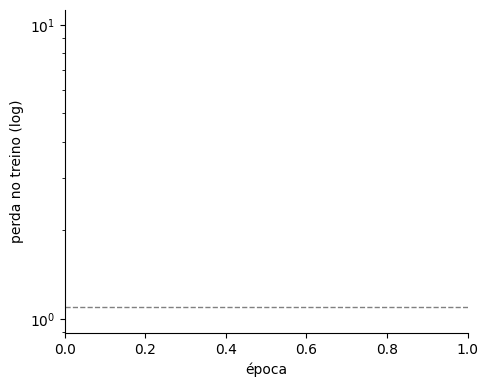

In [14]:
# Para ver: as curvas de perda dos treinos da B2 (rode depois de preencher a célula acima).
for nome in ["modelo", "m_zeros", "m_lenta", "m_mom"]:
    if nome in globals():
        plt.plot(globals()[nome].historico["perda"], label=nome)
plt.axhline(np.log(3), color="gray", ls="--", lw=1)
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("perda no treino (log)"); plt.legend(frameon=False); plt.show()

## B3 — Extra: o otimizador Adam

O momentum acumula a **direção** do gradiente. O Adam, citado no fim da Aula 4, acumula também o seu **tamanho**, e dá a cada
parâmetro um passo na escala certa. Para cada parâmetro $\theta$, com gradiente $g$, a cada passo:

$$ t \leftarrow t + 1, \qquad m \leftarrow \beta_1 m + (1-\beta_1)\,g, \qquad v \leftarrow \beta_2 v + (1-\beta_2)\,g^2 $$
$$ \hat m = \frac{m}{1-\beta_1^{\,t}}, \qquad \hat v = \frac{v}{1-\beta_2^{\,t}}, \qquad \theta \leftarrow \theta - \eta\,\frac{\hat m}{\sqrt{\hat v} + \varepsilon} $$

O $g^2$ e a raiz são elemento a elemento. As divisões por $1-\beta^t$ corrigem o começo, quando $m$ e $v$ ainda estão perto de zero.

Escreva a classe **`MLPAdam`**, filha da `MLP` da aula, seguindo **exatamente** esta especificação:

1. No `__init__`, depois do `super().__init__(...)`: `self.beta1 = 0.9`, `self.beta2 = 0.999`, `self.eps = 1e-8`,
   os dicionários `self.m` e `self.v` com um array de zeros por parâmetro (como `self.vel`) e `self.t = 0`.
2. Reescreva **só** o método `passo(self, grads, eta, beta=0.0)`: aumente `t` **uma vez por chamada** e aplique as equações
   acima a **todos** os parâmetros. O argumento `beta` existe só para manter a assinatura do `treinar` e é **ignorado**.
3. Não mexa no `treinar`: ele já chama o `passo` a cada mini-lote.

Depois, treine a sua rede com o Adam, com a inicialização recomendada, `eta=0.01`, `epocas=50`, o seu lote e `seed=MATRICULA`
no construtor e no `treinar`:

- **`q7_perda`**: a perda final no treino.
- **`q7_acuracia`**: a acurácia no teste, entre 0 e 1.

A classe será testada em redes e gradientes que você não conhece, comparando com a especificação acima.

In [15]:
class MLPAdam(MLP):
    def __init__(self, camadas, ativacao="relu", init="he", seed=0):
        super().__init__(camadas, ativacao, init, seed)
        self.beta1, self.beta2, self.eps = 0.9, 0.999, 1e-8
        # 1. Crie self.m e self.v (um array de zeros por parâmetro, como self.vel) e self.t = 0.

    def passo(self, grads, eta, beta=0.0):
        # 2. Aumente self.t uma vez. Depois, para cada chave k de self.params, com g = grads["d" + k]:
        #    atualize self.m[k] e self.v[k], calcule m_hat e v_hat e atualize self.params[k].
        #    O argumento beta é ignorado: o Adam usa self.beta1 e self.beta2.
        pass

In [16]:
# Passo 1: treine com o Adam.
#          Apague o # do começo das linhas e troque cada ... pelo valor pedido no enunciado.
# m_adam = MLPAdam([4, h, 3], ativ, init=..., seed=MATRICULA)
# m_adam.treinar(X_tr, Y_tr, eta=..., epocas=50, batch=lote, seed=MATRICULA)

# Passo 2: responda. Compare com a B2: o Adam chegou mais longe com uma taxa 10 vezes menor?
q7_perda = None      # m_adam.historico["perda"][-1]
q7_acuracia = None   # acurácia no teste (entre 0 e 1)

## 🔒 Verificação final

Esta célula **não** diz se as respostas estão certas. Ela só confere se todas foram preenchidas no formato esperado
e faz testes simples na sua `backward_geral` (o *gradient check* das três saídas) e na sua `MLPAdam` (o primeiro passo).

In [17]:
def verificar():
    g, ok = globals(), True
    def falha(msg):
        nonlocal ok; ok = False; print("✗", msg)
    if not isinstance(g.get("MATRICULA"), int): falha("MATRICULA não preenchida (use só dígitos, sem aspas).")
    if not str(g.get("NOME", "")).strip(): falha("NOME não preenchido.")
    formatos = {"q1_delta2": (2,), "q1_dW2": (2, 2), "q1_delta1": (2,), "q1_dW1": (2, 2),
                "q2_db2": (3,), "q2_erros": (4,), "q2_defeito": "1, 2 ou 3", "q3_mse_teste": "número",
                "q5_w1": (2,), "q5_w2": (2,), "q5_fator": "número", "q5_eta_max": "número", "q5_w2_mom": (2,),
                "q6_passos": "inteiro", "q6_perda": "número", "q6_acuracia": "entre 0 e 1",
                "q6_perda_zeros": "número", "q6_perda_lenta": "número", "q6_perda_momentum": "número",
                "q7_perda": "número", "q7_acuracia": "entre 0 e 1"}
    nomes = {(2,): "2 números", (3,): "3 números", (4,): "4 números", (2, 2): "matriz 2x2"}
    for nome, fmt in formatos.items():
        v = g.get(nome)
        try:
            a = np.asarray(v, dtype=float)
            if v is None or np.isnan(a).any(): raise ValueError
            if isinstance(fmt, tuple):
                if a.shape != fmt: raise ValueError
            else:
                if a.shape != (): raise ValueError
                if fmt in ("inteiro", "1, 2 ou 3") and float(a) != int(a): raise ValueError
                if fmt == "1, 2 ou 3" and int(a) not in (1, 2, 3): raise ValueError
                if fmt == "entre 0 e 1" and not 0 <= float(a) <= 1: raise ValueError
        except Exception:
            falha(f"{nome}: esperado {nomes.get(fmt, fmt)}, encontrado {v!r}")
    try:
        rng = np.random.default_rng(7); Xt = rng.normal(size=(5, 3))
        for s, Yt in [("softmax", one_hot(rng.integers(0, 2, 5), 2)), ("sigmoid", rng.integers(0, 2, (5, 2)).astype(float)),
                      ("linear", rng.normal(size=(5, 2)))]:
            e = gradient_check_geral(Xt, Yt, inicializa([3, 4, 2], 1.0, seed=2), "tanh", s, backward_fn=backward_geral)
            if max(e.values()) > 1e-7: falha(f"backward_geral com saida='{s}' não passa no gradient check.")
    except Exception as ex:
        falha(f"backward_geral gerou erro: {type(ex).__name__}: {ex}")
    try:
        m = MLPAdam([3, 4, 2], "tanh", init="xavier", seed=3)
        antes = {k: v.copy() for k, v in m.params.items()}
        grads = {"d" + k: np.random.default_rng(4).normal(size=v.shape) for k, v in m.params.items()}
        m.passo(grads, 0.01)
        if getattr(m, "t", None) != 1:
            falha("MLPAdam: depois de um passo, self.t deveria valer 1.")
        elif not all(np.allclose(np.abs(antes[k] - m.params[k]), 0.01, atol=1e-5) for k in antes):
            falha("MLPAdam: no primeiro passo, cada parâmetro deveria andar quase exatamente eta.")
    except Exception as ex:
        falha(f"MLPAdam gerou erro: {type(ex).__name__}: {ex}")
    print("✓ Tudo preenchido no formato esperado. Pode baixar o .ipynb e entregar." if ok
          else "\nCorrija os itens acima antes de entregar.")

verificar()

✗ q1_delta2: esperado 2 números, encontrado None
✗ q1_dW2: esperado matriz 2x2, encontrado None
✗ q1_delta1: esperado 2 números, encontrado None
✗ q1_dW1: esperado matriz 2x2, encontrado None
✗ q2_db2: esperado 3 números, encontrado None
✗ q2_erros: esperado 4 números, encontrado None
✗ q2_defeito: esperado 1, 2 ou 3, encontrado None
✗ q3_mse_teste: esperado número, encontrado None
✗ q5_w1: esperado 2 números, encontrado None
✗ q5_w2: esperado 2 números, encontrado None
✗ q5_fator: esperado número, encontrado None
✗ q5_eta_max: esperado número, encontrado None
✗ q5_w2_mom: esperado 2 números, encontrado None
✗ q6_passos: esperado inteiro, encontrado None
✗ q6_perda: esperado número, encontrado None
✗ q6_acuracia: esperado entre 0 e 1, encontrado None
✗ q6_perda_zeros: esperado número, encontrado None
✗ q6_perda_lenta: esperado número, encontrado None
✗ q6_perda_momentum: esperado número, encontrado None
✗ q7_perda: esperado número, encontrado None
✗ q7_acuracia: esperado entre 0 e 1, e